# k-nearest neighbours

A linear model learns weights, and a tree learns splits. *k*-nearest neighbours (k-NN) learns nothing of the kind: it keeps its training rows, and to predict for a new row it looks for the *k* training rows most similar to it. In classification it predicts their most common class; in regression, the average of their targets. The training rows themselves are the model, which is why k-NN is called **instance-based**, or **lazy**: the work is done when predicting, not when training. Most models, such as linear models and trees, are **model-based** instead: training compresses the rows into parameters, weights or splits, and the rows aren't needed to predict.

![With k = 3 the new point is classified as a red triangle; with k = 5, as a blue square](img/knn_classification.svg)

*Figure: Antti Ajanki, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:KnnClassification.svg), with a white background added.*

In the figure, the three nearest neighbours of the green point are two red triangles and one blue square, so with *k* = 3 it is a red triangle. With *k* = 5, three of its five neighbours are blue squares, and the prediction changes. How the regions of each class change as *k* grows:

![The regions where k-NN predicts each class, for a growing k](img/knn-decision-surface.gif)

*Animation: Paolo Bonfini, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:KNN_decision_surface_animation.gif).*

## A small example by hand

Six training points of two classes, and a new point to classify:

In [ ]:
import numpy as np
import pandas as pd

points = pd.DataFrame({
    "x1": [1, 1.5, 2, 6, 6.5, 7],
    "x2": [1, 2, 1, 6, 5, 6],
    "class": [0, 0, 0, 1, 1, 1],
}, index=["P1", "P2", "P3", "P4", "P5", "P6"])
new_point = np.array([5, 4])
points

,x1,x2,class
P1,1.0,1,0
P2,1.5,2,0
P3,2.0,1,0
P4,6.0,6,1
P5,6.5,5,1
P6,7.0,6,1


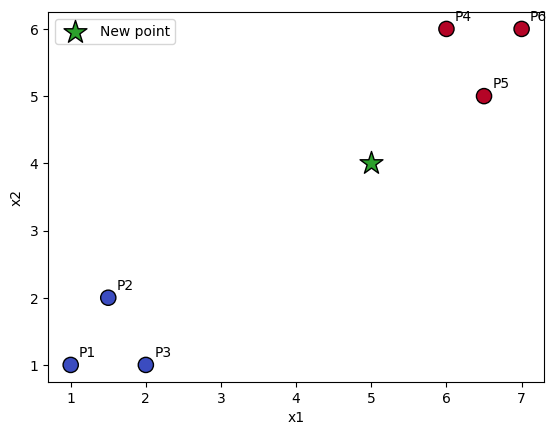

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(points["x1"], points["x2"], c=points["class"], cmap="coolwarm", s=120, edgecolors="k")
for name, row in points.iterrows():
    plt.annotate(name, (row["x1"], row["x2"]), xytext=(6, 6), textcoords="offset points")
plt.scatter(*new_point, marker="*", s=300, color="tab:green", edgecolors="k", label="New point")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.show()

Similarity is measured as a distance. The usual one is the **Euclidean distance**, the length of the straight line between two points: with features $x_1$ and $x_2$,

$$d = \sqrt{(x_1 - x_1')^2 + (x_2 - x_2')^2}$$

and with more features, one more squared difference under the root for each. From the new point to each training point, sorted:

In [ ]:
points["distance"] = np.sqrt(((points[["x1", "x2"]] - new_point) ** 2).sum(axis=1))
points.sort_values("distance").round(3)

,x1,x2,class,distance
P5,6.5,5,1,1.803
P4,6.0,6,1,2.236
P6,7.0,6,1,2.828
P2,1.5,2,0,4.031
P3,2.0,1,0,4.243
P1,1.0,1,0,5.000


`KNeighborsClassifier` finds the same neighbours. `predict_proba` gives the share of the *k* neighbours that belong to each class:

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

X_points = points[["x1", "x2"]]
y_points = points["class"]
new_row = pd.DataFrame([new_point], columns=["x1", "x2"])

pd.DataFrame({
    k: {
        "share of class 0": KNeighborsClassifier(n_neighbors=k).fit(X_points, y_points).predict_proba(new_row)[0, 0],
        "predicted class": KNeighborsClassifier(n_neighbors=k).fit(X_points, y_points).predict(new_row)[0],
    }
    for k in (1, 3, 5)
}).T.rename_axis("k")

,share of class 0,predicted class
k,,
1,0.0,1.0
3,0.0,1.0
5,0.4,1.0


The three nearest points all belong to class 1, so with *k* = 1 and *k* = 3 the prediction is class 1 with no hesitation. With *k* = 5, two points of class 0 join the vote: three against two, still class 1, but the share of class 0 rises to 0.4. With an even *k* a vote can tie, and scikit-learn then takes the class that comes first in order, which is one reason an odd *k* is common with two classes.

## Choosing *k*

*k* decides how flexible the model is. With *k* = 1, every training point decides the prediction around it, noise included; as *k* grows, each prediction averages over more points and the model becomes smoother, until, with *k* equal to the number of rows, it predicts the majority class everywhere. The two noisy half-moons of [random forests](../tree-based/random_forests.ipynb) show it:

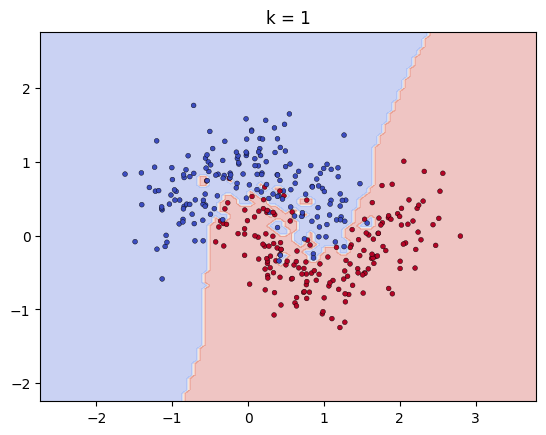

In [ ]:
from sklearn.datasets import make_moons
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split

X_moons, y_moons = make_moons(n_samples=500, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)


def plot_boundary(k):
    classifier = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    DecisionBoundaryDisplay.from_estimator(classifier, X_moons, response_method="predict", alpha=0.3, cmap="coolwarm")
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=12, cmap="coolwarm", edgecolors="k", linewidths=0.3)
    plt.title(f"k = {k}")
    plt.show()


plot_boundary(1)

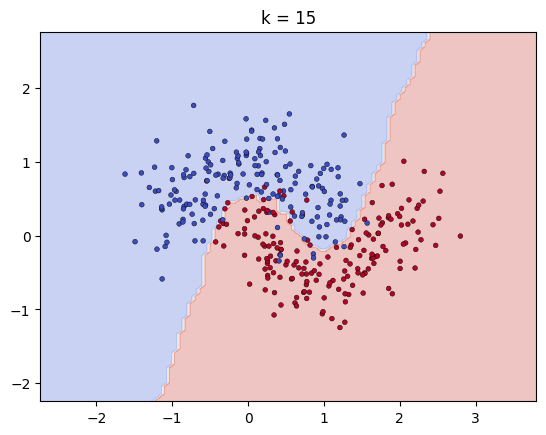

In [ ]:
plot_boundary(15)

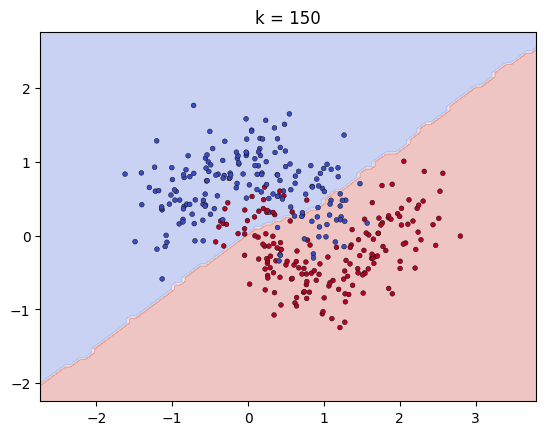

In [ ]:
plot_boundary(150)

With *k* = 1 the boundary bends around every training point, including the points of one moon that lie inside the other: small islands that a new point would fall into by chance. With *k* = 15 it follows the shape of the two moons. With *k* = 150, almost half of the 350 training points vote on every prediction, and the boundary flattens into a nearly straight diagonal that ignores the curve of the moons.

The share of points classified correctly (the *accuracy*), on both sets, for many values of *k*:

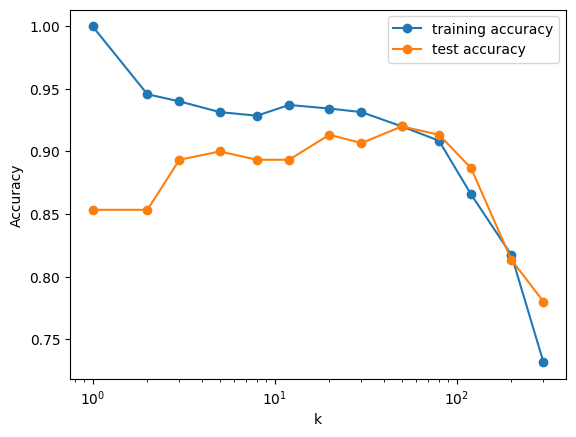

In [ ]:
k_values = [1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200, 300]
accuracy_by_k = pd.DataFrame({
    k: {
        "training accuracy": (model := KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)).score(X_train, y_train),
        "test accuracy": model.score(X_test, y_test),
    }
    for k in k_values
}).T.rename_axis("k")
accuracy_by_k.plot(marker="o", logx=True)
plt.ylabel("Accuracy")
plt.show()

The same story as the depth of a tree in [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb), in mirror image: a small *k* is a flexible model, a large *k* a rigid one. With *k* = 1 the training accuracy is perfect, since every training point is its own nearest neighbour, and the test accuracy is only 0.85. Between about 20 and 80 neighbours the test accuracy reaches 0.91 to 0.92; beyond that the model underfits and both accuracies fall. Choosing *k* by this test curve would make its test score optimistic: [Validation and model selection](../../ml-fundamentals/validation_and_model_selection.ipynb) and [Cross-validation and hyperparameter search](../../ml-fundamentals/cross_validation_and_search.ipynb) choose it honestly.

## Regression

For regression, the prediction is the average target of the *k* neighbours. Five training points, and the prediction at $x = 4$ for *k* = 1, 2 and 3:

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

five_points = pd.DataFrame({"x": [1, 1.7, 3.2, 5, 6], "y": [4, 6, 6, 3, 2]})
at_four = pd.DataFrame({"x": [4]})
pd.Series({
    k: KNeighborsRegressor(n_neighbors=k).fit(five_points[["x"]], five_points["y"]).predict(at_four)[0]
    for k in (1, 2, 3)
}, name="prediction at x = 4").rename_axis("k").round(2)

k
1    6.00
2    4.50
3    3.67
Name: prediction at x = 4, dtype: float64

The nearest point, at 3.2, alone gives 6. With *k* = 2 the point at 5 joins it, and the average falls to 4.5; with *k* = 3 the point at 6 joins too, and it falls to about 3.67. A prediction is always an average of training targets, never a value outside their range.

On the simulated salaries of [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb), with the same split, so that the errors compare with the line and the trees measured there:

In [ ]:
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=140).round(2)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=140)
salaries = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})
X_salaries_train, X_salaries_test, y_salaries_train, y_salaries_test = train_test_split(
    salaries[["YearsExperience"]], salaries["Salary"], test_size=0.2, random_state=42)

In [ ]:
pd.DataFrame({
    k: {
        "training MAE": mean_absolute_error(
            y_salaries_train,
            (model := KNeighborsRegressor(n_neighbors=k).fit(X_salaries_train, y_salaries_train)).predict(X_salaries_train)),
        "test MAE": mean_absolute_error(y_salaries_test, model.predict(X_salaries_test)),
    }
    for k in (1, 3, 5, 10, 20, 40)
}).T.rename_axis("k").round()

,training MAE,test MAE
k,,
1,190.0,4543.0
3,2418.0,4139.0
5,2658.0,4106.0
10,2912.0,3978.0
20,3083.0,4063.0
40,3347.0,4541.0


With *k* = 1 the model repeats the salary of the single closest employee: a training error of only 190 (not 0 because a few employees share their years of experience) and a test error of about 4,500. As *k* grows, the test error falls, to about 4,000 with *k* = 10, and then rises again: with *k* = 40, each prediction averages more than a third of the 112 training employees, and the model is as bad as with *k* = 1, too rigid instead of too flexible. None of them beats the straight line's 3,647 on the same rows: the salaries were simulated to grow linearly with experience, which a line describes exactly and an average of neighbours only approximates. And picking *k* = 10 by looking at these same 28 test rows would make its score optimistic, as [Validation and model selection](../../ml-fundamentals/validation_and_model_selection.ipynb) measures.

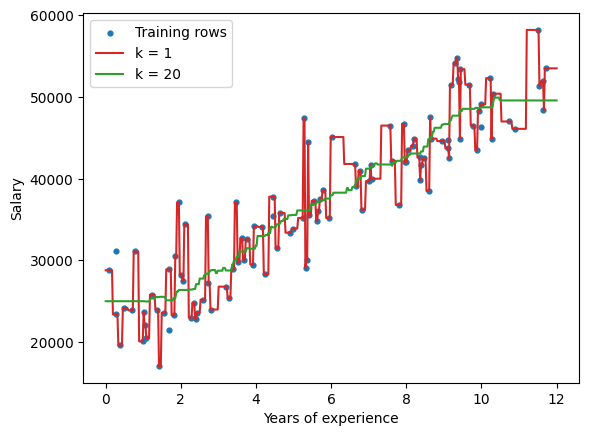

In [ ]:
grid = pd.DataFrame({"YearsExperience": np.linspace(0, 12, 500)})
plt.scatter(X_salaries_train, y_salaries_train, color="tab:blue", s=12, label="Training rows")
for k, color in ((1, "tab:red"), (20, "tab:green")):
    model = KNeighborsRegressor(n_neighbors=k).fit(X_salaries_train, y_salaries_train)
    plt.plot(grid, model.predict(grid), color=color, label=f"k = {k}")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

*k* = 1 passes through every training salary. *k* = 20 is a smooth staircase, but its ends are flat: near 0 and near 12 years of experience all the nearest neighbours lie on one side, so the prediction stops following the trend. The larger *k*, the wider those flat ends, a weakness of averaging neighbours that a line doesn't have.

## Why scaling matters

A distance adds up the differences of every feature, each in its own units. A feature measured in thousands then decides which rows are close, and one measured in tenths barely counts, whatever their importance. In the wine dataset (178 wines from three cultivars, 13 chemical measurements), proline goes up to 1,680 milligrams per litre while the colour hue stays below 2: without scaling, the distance between two wines is almost entirely their difference in proline, and the other twelve measurements barely count.

The cure is to put every feature on a comparable scale before measuring distances, typically by standardising it (subtracting its mean and dividing by its standard deviation, both computed on the training rows only, as in [California housing, step by step](../../basic-workflows/california_by_hand.ipynb)). On the wine data it raises the accuracy of k-NN from 71% to 96%. For a model built on distances, scaling decides the result: [Scaling numerical features](../../../data-preparation/feature_scaling.ipynb) shows the boundaries it changes, compares the scalers, and lists which models need scaling and which don't.

## Costs and limits

- **Cheap to train, expensive to predict.** `fit` stores the rows, and may build a structure (a *k*-d tree or a ball tree) to find neighbours faster. Every prediction still searches the training rows, so its cost grows with their number, and the whole training set must be kept in memory.
- **The curse of dimensionality.** With many features, the distances between all pairs of points become almost equal, so the "nearest" neighbours are hardly nearer than any others. k-NN works best with a few meaningful features.
- **Irrelevant features add noise to every distance**, since all features count equally. Selecting or weighting features matters more than for trees.
- **No extrapolation:** like a tree, it predicts averages of training targets, never beyond them.

## Case-based reasoning

k-NN is the simplest form of an older idea from AI, **case-based reasoning**: solve a new problem from the most similar past ones. A help desk that reuses the fix of the most similar past ticket works this way, and so does an appraiser who values a flat from similar flats sold nearby. Agnar Aamodt and Enric Plaza (1994) described it as a cycle of four steps:

1. **Retrieve** the most similar past cases.
2. **Reuse** their solution for the new problem.
3. **Revise** it: check whether it works, and repair it if it doesn't.
4. **Retain** the new case with its solution, so that the next problem has one more case to compare with.

k-NN does the first two: it retrieves the *k* nearest rows and reuses their answers, by vote or by average. Keeping the cases instead of a model has two advantages that the costs above don't show:

- **A new labelled row only has to be stored**, and the next prediction can already use it. A model-based method usually has to be trained again to learn from it.
- **A prediction can be explained by its cases:** `kneighbors` returns the rows it came from, which a person can check one by one.

The idea lives on well beyond this algorithm. Searching for the nearest stored items to a query is how recommendation systems find similar products, and how retrieval systems find the passages most similar to a question, once texts are turned into vectors. Where case-based reasoning comes from, and how it answered the rules of expert systems: [Rules and expert systems](../../../concepts/deep-dives/classical-ai/rules_and_expert_systems.ipynb), in the classical AI deep dive.

## Distances and weights *(deep dive)*

- **Euclidean distance** is the default. The **Manhattan distance** adds the absolute differences instead of squaring them: $d = \sum_i |x_i - x_i'|$, the distance along a grid of streets. Both are cases of the **Minkowski distance**, $d = \left(\sum_i |x_i - x_i'|^p\right)^{1/p}$, with $p = 2$ and $p = 1$. scikit-learn's default is `metric="minkowski"` with `p=2`: the Euclidean distance.
- `weights="distance"` makes closer neighbours count more than distant ones, instead of all *k* counting equally. How it changes the decision boundary, and why it makes the training accuracy meaningless: [Uniform and distance weights](deep-dives/knn_weights.ipynb).

## Further material

- [scikit-learn user guide: nearest neighbours](https://scikit-learn.org/stable/modules/neighbors.html)
- Scaling in depth, with the other scalers and the models that don't need it: [Scaling numerical features](../../../data-preparation/feature_scaling.ipynb)